In [ ]:
# Import all Libraries

import os
import time
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [ ]:
# Mount Google Drive

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")

print("GPU devices:",
    GPUS if GPUS else "NONE - CPU training will be substantially slower")

# Configure GPU memory growth
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("GPU memory configuration:", e)

# Enable mixed precision when a GPU is available.
# The final classification layer will use float32.
if GPUS:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print(
        "Mixed precision policy:",
        mixed_precision.global_policy()
    )
else:
    print("Mixed precision disabled because no GPU was detected.")

TensorFlow version: 2.21.0
GPU devices: NONE - CPU training will be substantially slower
Mixed precision disabled because no GPU was detected.


In [ ]:
# Locate project, split CSVs, and dataset folder

MY_DRIVE = "/content/drive/MyDrive"

PROJECT_CANDIDATES = [
    os.path.join(MY_DRIVE, "Brain_Tumor_CNN_Project"),
    os.path.join(MY_DRIVE, "brain_tumor"),
]

PROJECT_DIR = next(
    (p for p in PROJECT_CANDIDATES
    if os.path.isdir(os.path.join(p, "results"))),None)

if PROJECT_DIR is None:
    PROJECT_DIR = next(
        (p for p in PROJECT_CANDIDATES if os.path.isdir(p)),None)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Project folder not found. Expected 'Brain_Tumor_CNN_Project' "
        "or 'brain_tumor' in My Drive. Update PROJECT_CANDIDATES.")

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

In [ ]:
def find_first_existing(paths):
    return next(
        (p for p in paths if os.path.isfile(p)),
        None)

# Find training CSV
train_csv = find_first_existing([
    os.path.join(RESULTS_DIR, "train_split.csv"),
    os.path.join(RESULTS_DIR, "train.csv"),])

# Find validation CSV
val_csv = find_first_existing([
    os.path.join(RESULTS_DIR, "validation_split.csv"),
    os.path.join(RESULTS_DIR, "val_split.csv"),
    os.path.join(RESULTS_DIR, "validation.csv"),])

# Find test CSV
test_csv = find_first_existing([
    os.path.join(RESULTS_DIR, "test_split.csv"),
    os.path.join(RESULTS_DIR, "test.csv"),])

if not all([train_csv, val_csv, test_csv]):
    raise FileNotFoundError(
        "Could not find all train, validation, and test CSV files "
        f"in {RESULTS_DIR}. Check the filenames.")

In [ ]:
# Possible dataset locations
DATASET_CANDIDATES = [
    os.path.join(
        PROJECT_DIR,
        "dataset",
        "Epic and CSCR hospital Dataset"
    ),
    os.path.join(
        PROJECT_DIR,
        "dataset",
        "Epic and CSCR hospital Dataset-zip"
    ),
    os.path.join(PROJECT_DIR, "dataset"),
    os.path.join(
        MY_DRIVE,
        "brain_tumor",
        "dataset",
        "Epic and CSCR hospital Dataset"
    ),
    os.path.join(
        MY_DRIVE,
        "brain_tumor",
        "dataset",
        "Epic and CSCR hospital Dataset-zip"
    ),
]

IMAGE_EXTS = (".jpg",".jpeg",".png",".bmp",".webp")


In [ ]:
DRIVE_DATASET_DIR = next(
    (p for p in DATASET_CANDIDATES
        if os.path.isdir(p)
        and any(
            os.path.isdir(os.path.join(root, folder))
            for root, dirs, files in os.walk(p)
            for folder in ("Train", "Test"))),
    None)

if DRIVE_DATASET_DIR is None:
    DRIVE_DATASET_DIR = next(
        (p for p in DATASET_CANDIDATES
            if os.path.isdir(p)
            and os.path.basename(p) != "dataset"),
        None)

if DRIVE_DATASET_DIR is None:
    raise FileNotFoundError(
        "Could not locate the extracted image dataset. "
        "Update DATASET_CANDIDATES to match your Drive folders.")

In [ ]:
# Copy dataset to faster local Colab storage
LOCAL_DATASET_DIR = "/content/brain_tumor_dataset"

if os.path.abspath(DRIVE_DATASET_DIR) != os.path.abspath(LOCAL_DATASET_DIR):
    if not os.path.isdir(LOCAL_DATASET_DIR):
        print(
            "Copying dataset to local Colab storage. "
            "The first copy may take some time...")

        shutil.copytree(
            DRIVE_DATASET_DIR,
            LOCAL_DATASET_DIR)

        print("Dataset copy completed.")
    else:
        print("Using existing local dataset copy.")

DATASET_DIR = LOCAL_DATASET_DIR

print("\nPROJECT:", PROJECT_DIR)
print("DATASET SOURCE:", DRIVE_DATASET_DIR)
print("LOCAL DATASET:", DATASET_DIR)

print("\nTRAIN CSV:", train_csv)
print("VALIDATION CSV:", val_csv)
print("TEST CSV:", test_csv)

print("\nMODELS OUTPUT:", MODELS_DIR)
print("RESULTS OUTPUT:", RESULTS_DIR)

Copying dataset to local Colab storage. The first copy may take some time...
Dataset copy completed.

PROJECT: /content/drive/MyDrive/Brain_Tumor_CNN_Project
DATASET SOURCE: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset
LOCAL DATASET: /content/brain_tumor_dataset

TRAIN CSV: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/train_split.csv
VALIDATION CSV: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/validation_split.csv
TEST CSV: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/test_split.csv

MODELS OUTPUT: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models
RESULTS OUTPUT: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results


In [ ]:
# Read split CSVs and validate schema/labels

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)]:

    required_columns = {"image_path", "label"}

    if not required_columns.issubset(frame.columns):
        raise ValueError(
            f"{split_name} CSV must contain "
            "'image_path' and 'label'. "
            f"Found columns: {frame.columns.tolist()}"
        )

    frame["label"] = pd.to_numeric(
        frame["label"],
        errors="raise"
    ).astype("int32")

    labels = set(frame["label"].unique())

    if not labels.issubset({0, 1}):
        raise ValueError(
            f"{split_name} labels must be encoded as 0 and 1. "
            f"Found: {sorted(labels)}"
        )

    if len(frame) == 0:
        raise ValueError(
            f"{split_name} dataset is empty."
        )

In [ ]:
CLASS_NAMES = ["Non-Tumourous","Tumourous"]

print(f"Training samples:   {len(train_df):,}")
print(f"Validation samples: {len(val_df):,}")
print(f"Test samples:       {len(test_df):,}")

print("\nTraining class distribution:")

print(train_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: CLASS_NAMES[0],
        1: CLASS_NAMES[1]})
    )

Training samples:   4,844
Validation samples: 1,930
Test samples:       2,093

Training class distribution:
label
Non-Tumourous     675
Tumourous        4169
Name: count, dtype: int64


In [ ]:
# Map CSV paths to local image files and verify every split

# Build an index of local image filenames.
# This allows unique filenames to be resolved even if the
# original CSV contains an old Google Drive path.

local_files = {}

for root, _, filenames in os.walk(DATASET_DIR):
    for filename in filenames:
        if filename.lower().endswith(IMAGE_EXTS):
            local_files.setdefault(
                filename,[]
            ).append(
                os.path.join(root, filename)
            )

source_root = os.path.abspath(DRIVE_DATASET_DIR)
local_root = os.path.abspath(DATASET_DIR)


def resolve_image_path(raw_path):
    raw_path = str(raw_path)

    # Case 1: The path already points to a local file.
    if (os.path.isfile(raw_path)
        and os.path.abspath(raw_path).startswith(
            local_root + os.sep)):
        return raw_path

    # Case 2: Convert a Drive dataset path to a local path.
    try:
        rel = os.path.relpath(
            os.path.abspath(raw_path),
            source_root)

        candidate = os.path.join(
            local_root,
            rel)

        if os.path.isfile(candidate):
            return candidate

    except Exception:
        pass

    # Case 3: Find common path suffixes such as Train/class/image.jpg.
    parts = Path(raw_path.replace("\\", "/")).parts

    lower_parts = [part.lower()for part in parts]

    marker = next(
        (i for i, part in enumerate(lower_parts)
            if part in {
                "train",
                "test",
                "validation",
                "val"}),
        None)

    if marker is not None:
        suffix = parts[marker:]
        candidate = os.path.join(
            local_root,
            *suffix)

        if os.path.isfile(candidate):
            return candidate

        # Handle an additional enclosing folder.
        for root, _, _ in os.walk(local_root):
            candidate = os.path.join(root,*suffix)

            if os.path.isfile(candidate):
                return candidate

    # Case 4: Fall back to a unique filename match.
    matches = local_files.get(
        os.path.basename(raw_path),[])

    if len(matches) == 1:
        return matches[0]

    # Leave unresolved paths unchanged so validation can report them.
    return raw_path

In [ ]:
# Resolve paths in all splits.
for frame in (train_df, val_df, test_df):
    frame["image_path"] = frame["image_path"].map(resolve_image_path)

# Validate paths.
for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)]:

    missing = [
        p for p in frame["image_path"]
        if not os.path.isfile(p)]

    print(f"{split_name}: {len(missing)} missing image path(s)")

    if missing:
        raise FileNotFoundError(
            "Some image paths could not be resolved.\n"
            "Example paths:\n"
            + "\n".join(map(str, missing[:10])))

train: 0 missing image path(s)
validation: 0 missing image path(s)
test: 0 missing image path(s)


In [ ]:
# Save resolved CSVs for reproducibility.
for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)]:

    frame.to_csv(
        os.path.join(
            RESULTS_DIR,
            f"efficientnetv2s_{split_name}_resolved.csv"),
        index=False)

print("\nAll image paths verified successfully.")


All image paths verified successfully.


In [ ]:
# Configure image size, batch size, and input pipeline

IMG_SIZE = (224, 224)

# Adjust batch size according to available GPU memory.
BATCH_SIZE = 16 if GPUS else 8
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize_image(image_path, label):

    # Read image from local storage.
    image_bytes = tf.io.read_file(image_path)

    # Decode JPEG, PNG, BMP, or WebP images.
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False)

    image.set_shape([None, None, 3])

    # Resize image.
    image = tf.image.resize(
        image,
        IMG_SIZE,
        antialias=False)

    # EfficientNetV2's built-in preprocessing expects
    # image pixel values in the 0-255 range.
    image = tf.cast(image,tf.float32)
    label = tf.cast(label,tf.float32)

    return image, label


def make_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    # Shuffle training data only.
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 2048),
            seed=SEED,
            reshuffle_each_iteration=True)

    # Parallel image loading and preprocessing.
    ds = ds.map(
        decode_resize_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training)

    # Create batches.
    ds = ds.batch(BATCH_SIZE,drop_remainder=False)

    # Prepare subsequent batches in advance.
    ds = ds.prefetch(AUTOTUNE)

    return ds

In [ ]:
# Create datasets.
train_ds = make_dataset(train_df,training=True)
val_ds = make_dataset(val_df,training=False)
test_ds = make_dataset(test_df,training=False)

# Inspect one batch.
sample_images, sample_labels = next(iter(train_ds.take(1)))

print("Batch images:",sample_images.shape,sample_images.dtype)
print("Batch labels:",sample_labels.shape,sample_labels.dtype)

print("Pixel range:",float(tf.reduce_min(sample_images)),
    "to",float(tf.reduce_max(sample_images)))

print("Batch size:", BATCH_SIZE)
print("Image size:", IMG_SIZE)

Batch images: (8, 224, 224, 3) <dtype: 'float32'>
Batch labels: (8,) <dtype: 'float32'>
Pixel range: 0.0 to 250.0
Batch size: 8
Image size: (224, 224)


In [ ]:
# Calculate class weights using training data only

y_train = train_df["label"].to_numpy().astype(int)
classes = np.unique(y_train)

if not np.array_equal(classes, np.array([0, 1])):
    raise ValueError(
        "Training split must contain both labels 0 and 1. "
        f"Found: {classes}")

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)}

print("Class weights:")
for label, weight in class_weights.items():
    print(f"{CLASS_NAMES[label]} ({label}): {weight:.4f}")

Class weights:
Non-Tumourous (0): 3.5881
Tumourous (1): 0.5810


In [ ]:
# Build EfficientNetV2S model
from tensorflow.keras import layers

base_model = tf.keras.applications.EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
    include_preprocessing=True)

# Freeze the pretrained backbone during initial training.
base_model.trainable = False

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Define model input.
inputs = layers.Input(shape=(*IMG_SIZE, 3),name="image")

# Extract features using EfficientNetV2S.
x = base_model(inputs,training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.25, name="head_dropout")(x)

# Sigmoid output for binary classification.
# float32 improves numerical stability with mixed precision.
outputs = layers.Dense(1,
    activation="sigmoid",
    dtype="float32",
    name="tumour_probability")(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetV2S_BrainTumour")

In [ ]:
# Compile model.
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

print("Trainable parameters:",sum(int(tf.size(v)) for v in model.trainable_variables))
print("Total parameters:", model.count_params())

Model: "EfficientNetV2S_BrainTumour"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 7, 7, 1280)     │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tumour_probability (Dense)      │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,332,641 (77.56 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

Trainable parameters: 1281
Total parameters: 20332641


In [ ]:
# Train Phase 1 - Feature extraction

V2S_BEST_PATH = os.path.join(MODELS_DIR,"best_efficientnetv2s.keras")
V2S_PHASE1_PATH = os.path.join(MODELS_DIR,"efficientnetv2s_phase1_best.keras")

callbacks_phase1 = [

    # Save the best model based on validation loss.
    tf.keras.callbacks.ModelCheckpoint(
        V2S_PHASE1_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1),

    # Stop if validation loss stops improving.
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1),

    # Reduce learning rate when validation loss plateaus.
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )]

start_time = time.time()

In [ ]:
history_p1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=callbacks_phase1,
    verbose=1
)

phase1_seconds = time.time() - start_time
print(f"Phase 1 training time: "f"{phase1_seconds / 60:.2f} minutes")

Epoch 1/5
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8769 - auc: 0.9226 - loss: 0.3803 - precision: 0.9657 - recall: 0.8876
Epoch 1: val_loss improved from None to 0.20068, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetv2s_phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetv2s_phase1_best.keras
606/606 ━━━━━━━━━━━━━━━━━━━━ 1253s 2s/step - accuracy: 0.9077 - auc: 0.9555 - loss: 0.2905 - precision: 0.9757 - recall: 0.9156 - val_accuracy: 0.9301 - val_auc: 0.9873 - val_loss: 0.2007 - val_precision: 0.9902 - val_recall: 0.9215 - learning_rate: 0.0010
Epoch 2/5
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9339 - auc: 0.9796 - loss: 0.1868 - precision: 0.9875 - recall: 0.9349
Epoch 2: val_loss improved from 0.20068 to 0.12742, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetv2s_phase1_best.keras

Epoch 2: finished saving model to /conte

In [ ]:
# Change to False if you need a shorter training run.
RUN_FINE_TUNING = True
history_p2 = None
phase2_seconds = 0.0

if RUN_FINE_TUNING:

    # Unfreeze the backbone.
    base_model.trainable = True

    # Freeze all except the final 20 layers.
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    # Keep BatchNormalization layers frozen.
    for layer in base_model.layers:
        if isinstance(layer,tf.keras.layers.BatchNormalization):
            layer.trainable = False

    # Recompile after changing trainable layers.
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]

    )

    callbacks_phase2 = [
        tf.keras.callbacks.ModelCheckpoint(
            V2S_BEST_PATH,
            monitor="val_loss",
            save_best_only=True,
            verbose=1),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=1,
            min_lr=1e-7,
            verbose=1)
    ]

    start_time = time.time()

    history_p2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        class_weight=class_weights,
        callbacks=callbacks_phase2,
        verbose=1
    )

    phase2_seconds = time.time() - start_time

    print(f"Phase 2 training time: "f"{phase2_seconds / 60:.2f} minutes")

Epoch 1/3
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9605 - auc: 0.9925 - loss: 0.1175 - precision: 0.9921 - recall: 0.9618
Epoch 1: val_loss improved from None to 0.11388, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetv2s.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetv2s.keras
606/606 ━━━━━━━━━━━━━━━━━━━━ 1395s 2s/step - accuracy: 0.9515 - auc: 0.9887 - loss: 0.1360 - precision: 0.9908 - recall: 0.9525 - val_accuracy: 0.9642 - val_auc: 0.9949 - val_loss: 0.1139 - val_precision: 0.9966 - val_recall: 0.9585 - learning_rate: 1.0000e-05
Epoch 2/3
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9546 - auc: 0.9923 - loss: 0.1170 - precision: 0.9962 - recall: 0.9512
Epoch 2: val_loss improved from 0.11388 to 0.08716, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetv2s.keras

Epoch 2: finished saving model to /content/drive/MyDrive/

In [ ]:
# If fine-tuning was disabled, save the Phase 1 model.
if not os.path.isfile(V2S_BEST_PATH):
    model.save(V2S_BEST_PATH)
    print("Saved the current model because "
        "the fine-tuning checkpoint was not created.")

print(f"Total training time: "f"{(phase1_seconds + phase2_seconds) / 60:.2f} minutes")

Total training time: 171.24 minutes


In [ ]:
# Plot training curves

def combine_histories(*histories):
    combined = {}

    for hist in histories:
        if hist is None:
            continue

        for key, values in hist.history.items():
            combined.setdefault(key,[]).extend(values)

    return combined

combined_history = combine_histories(history_p1,history_p2)

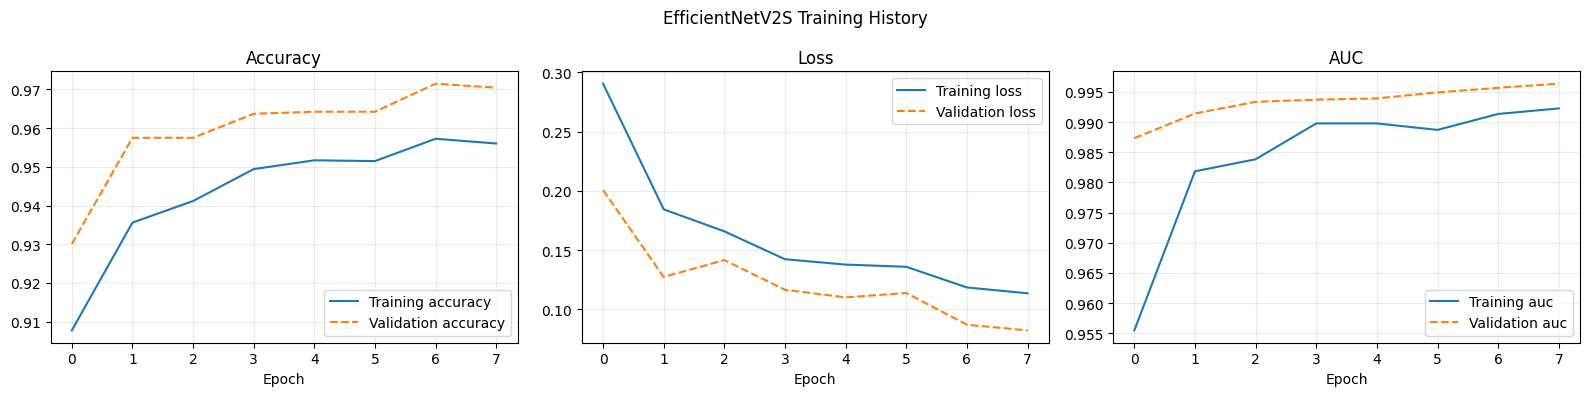

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(16, 4))
metrics_to_plot = [
    ("accuracy", "Accuracy"),
    ("loss", "Loss"),
    ("auc", "AUC")]

for ax, (metric, title) in zip(axes,metrics_to_plot):
    if metric in combined_history:
        ax.plot(combined_history[metric],label=f"Training {metric}")

    if "val_" + metric in combined_history:
        ax.plot(combined_history["val_" + metric],"--",label=f"Validation {metric}")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.25)
    ax.legend()

plt.suptitle("EfficientNetV2S Training History")
plt.tight_layout()
plt.show()

In [ ]:
# Load the best checkpoint and evaluate the test set
if os.path.isfile(V2S_BEST_PATH):
    best_model = tf.keras.models.load_model(V2S_BEST_PATH)

elif os.path.isfile(V2S_PHASE1_PATH):
    best_model = tf.keras.models.load_model(V2S_PHASE1_PATH)

else:
    raise FileNotFoundError(
        "No EfficientNetV2S checkpoint found. "
        "Run the training cells first.")


# Evaluate the selected model.
test_loss, test_acc, test_prec, test_rec, test_auc_metric = (
    best_model.evaluate(test_ds,verbose=1))

# Predict probabilities.
y_true = test_df["label"].to_numpy().astype(int)
y_prob = best_model.predict(test_ds,verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Calculate confusion matrix.
cm = confusion_matrix(y_true,y_pred,labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

# Calculate evaluation metrics.
test_f1 = f1_score(y_true,y_pred,zero_division=0)
specificity = (tn / (tn + fp) if (tn + fp) else np.nan)

try:
    roc_auc = roc_auc_score(y_true,y_prob)
except ValueError:
    roc_auc = np.nan

try:
    pr_auc = average_precision_score(y_true,y_prob)
except ValueError:
    pr_auc = np.nan

262/262 ━━━━━━━━━━━━━━━━━━━━ 378s 1s/step - accuracy: 0.9551 - auc: 0.9915 - loss: 0.1310 - precision: 0.9939 - recall: 0.9507
262/262 ━━━━━━━━━━━━━━━━━━━━ 376s 1s/step


In [ ]:
# Store measured test results.
v2s_metrics = {
    "Model": "EfficientNetV2S",
    "Accuracy": float(accuracy_score(y_true, y_pred)),
    "Precision": float(precision_score(y_true,y_pred,zero_division=0)),
    "Recall": float(recall_score(y_true,y_pred,zero_division=0)),
    "F1-score": float(test_f1),
    "Specificity": (float(specificity)
        if np.isfinite(specificity)
        else np.nan),
    "ROC-AUC": (float(roc_auc)
        if np.isfinite(roc_auc)
        else np.nan),
    "PR-AUC": (float(pr_auc)
        if np.isfinite(pr_auc)
        else np.nan),
    "Test loss": float(test_loss),
    "Training time (minutes)": float((phase1_seconds + phase2_seconds) / 60),
    "Test samples": int(len(test_df))}

In [ ]:
print("\n===== EfficientNetV2S Test Classification Report =====\n")
print(classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0))
print("Confusion matrix "
    "(rows = actual, columns = predicted):\n",cm)


===== EfficientNetV2S Test Classification Report =====

               precision    recall  f1-score   support

Non-Tumourous     0.8182    0.9742    0.8894       388
    Tumourous     0.9939    0.9507    0.9718      1705

     accuracy                         0.9551      2093
    macro avg     0.9060    0.9625    0.9306      2093
 weighted avg     0.9613    0.9551    0.9565      2093

Confusion matrix (rows = actual, columns = predicted):
 [[ 378   10]
 [  84 1621]]


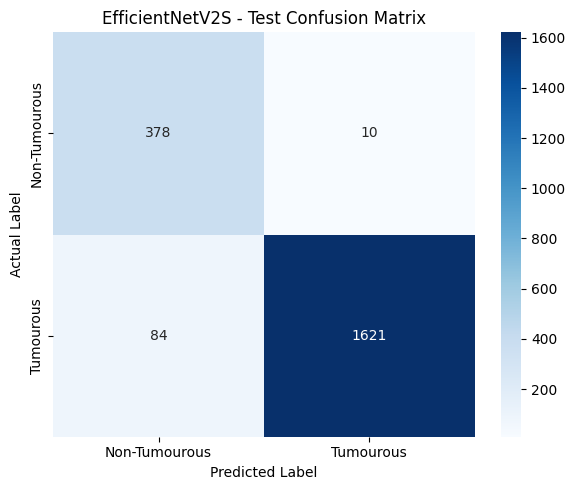

In [ ]:
# Plot confusion matrix.
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("EfficientNetV2S - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
# Save and display metrics.
v2s_metrics_df = pd.DataFrame([v2s_metrics])
display(v2s_metrics_df)

metrics_output_path = os.path.join(RESULTS_DIR,"efficientnetv2s_test_metrics.csv")
v2s_metrics_df.to_csv(
    metrics_output_path,
    index=False)

print("Metrics saved to:",metrics_output_path)

,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,PR-AUC,Test loss,Training time (minutes),Test samples
0,EfficientNetV2S,0.955088,0.993869,0.950733,0.971823,0.974227,0.991747,0.998184,0.131049,171.244096,2093


Metrics saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/efficientnetv2s_test_metrics.csv


In [ ]:
# Load previous model metrics and build comparison table

comparison_rows = [v2s_metrics.copy()]

def normalize_score(value):
    value = pd.to_numeric(value,errors="coerce")

    if pd.isna(value):
        return np.nan

    value = float(value)

    # Convert percentages to decimal scores.
    if value > 1.0:
        return value / 100.0

    return value


def first_matching_column(columns,candidates):
    lower_map = {
        str(c).strip().lower().replace("_", " "): c
        for c in columns}

    for candidate in candidates:
        for norm, original in lower_map.items():
            if candidate in norm:
                return original

    return None


def load_comparable_metrics(path,model_name):
    if not os.path.isfile(path):
        print("Metrics file not found; skipping:",path)
        return None

    try:
        frame = pd.read_csv(path)

    except Exception as exc:
        print(f"Could not read {path}: {exc}")
        return None

    if frame.empty:
        print("Metrics file is empty; skipping:",path)
        return None


    # Support files containing Metric and Score columns.
    if {"Metric", "Score"}.issubset(frame.columns):
        row = {}
        for _, rec in frame.iterrows():
            row[str(rec["Metric"]).strip().lower()] = normalize_score(rec["Score"])

        acc = next((v for k, v in row.items() if "accuracy" in k),np.nan)
        prec = next((v for k, v in row.items() if "precision" in k),np.nan)
        rec = next((v for k, v in row.items() if "recall" in k),np.nan)
        f1v = next((v for k, v in row.items() if "f1" in k),np.nan)
        auc = next((v for k, v in row.items() if "roc" in k and "auc" in k),np.nan)

        samples = np.nan

    else:
        row = frame.iloc[0].to_dict()

        acc_col = first_matching_column(frame.columns,["accuracy", "test acc"])
        prec_col = first_matching_column(frame.columns,["precision"])
        rec_col = first_matching_column(frame.columns,["recall", "sensitivity"])
        f1_col = first_matching_column(frame.columns,["f1", "f1 score", "f1-score"])
        auc_col = first_matching_column(frame.columns,["roc auc", "roc-auc", "auc"])
        sample_col = first_matching_column(frame.columns,["test samples", "n test", "sample count"])

        acc = (normalize_score(row[acc_col]) if acc_col else np.nan)
        prec = (normalize_score(row[prec_col]) if prec_col else np.nan)
        rec = (normalize_score(row[rec_col]) if rec_col else np.nan)
        f1v = (normalize_score(row[f1_col]) if f1_col else np.nan)
        auc = (normalize_score(row[auc_col]) if auc_col else np.nan)
        samples = (row[sample_col] if sample_col else np.nan)

    # Accuracy is required for inclusion.
    if not np.isfinite(acc):
        print("Could not identify accuracy in:",path)
        return None

    # Calculate F1 if it is not provided.
    if (
        not np.isfinite(f1v)
        and np.isfinite(prec)
        and np.isfinite(rec)
        and (prec + rec) > 0
    ):
        f1v = (2 * prec * rec) / (prec + rec)

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1v,
        "ROC-AUC": auc,
        "Training time (minutes)": np.nan,
        "Test samples": samples
    }

In [ ]:
# Possible metric file locations.
prior_files = [
    (os.path.join(RESULTS_DIR,"efficientnet_metrics.csv"),"EfficientNetB0"),
    (os.path.join(RESULTS_DIR,"efficientnet_b0_test_metrics.csv"),"EfficientNetB0"),
    (os.path.join(RESULTS_DIR,"test_metrics.csv"),"Custom CNN")
]


seen_models = set()

for path, name in prior_files:
    if name in seen_models:
        continue

    metrics = load_comparable_metrics(path,name)

    if metrics is not None:
        comparison_rows.append(metrics)

        seen_models.add(name)

In [ ]:
# Build comparison DataFrame.
comparison_df = pd.DataFrame(comparison_rows)

# Remove duplicate model names.
comparison_df = comparison_df.drop_duplicates(subset=["Model"],keep="first")
comparison_path = os.path.join(RESULTS_DIR,"model_comparison_v2s.csv")
comparison_df.to_csv(comparison_path,index=False)

# Display formatted results.
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Training time (minutes)": "{:.1f}"
    })
)

print("Comparison CSV saved:",comparison_path)
print("\nFor a fair comparison, confirm that all models "
    "used the same held-out test split and label mapping.")

,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,PR-AUC,Test loss,Training time (minutes),Test samples
0,EfficientNetV2S,0.9551,0.9939,0.9507,0.9718,0.974227,0.9917,0.998184,0.131049,171.2,2093.000000
1,EfficientNetB0,0.9618,0.9939,0.9589,0.9761,nan,0.9912,nan,nan,nan,nan
2,Custom CNN,0.9479,0.9744,0.9613,0.9678,nan,nan,nan,nan,nan,nan


Comparison CSV saved: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/model_comparison_v2s.csv

For a fair comparison, confirm that all models used the same held-out test split and label mapping.


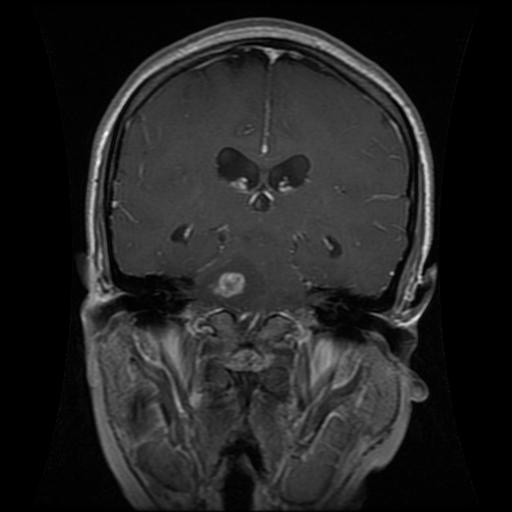

Image: 1049.jpg
Actual label: Tumourous
Predicted label: Tumourous
Predicted tumour probability: 0.9995


In [ ]:
# Sample prediction
from IPython.display import display
from PIL import Image

# Select the first image from the test set.
sample_idx = 0
sample_row = test_df.iloc[sample_idx]

display(Image.open(sample_row["image_path"]).convert("RGB"))

print("Image:",os.path.basename(sample_row["image_path"]))
print("Actual label:",CLASS_NAMES[int(y_true[sample_idx])])
print("Predicted label:",CLASS_NAMES[int(y_pred[sample_idx])])
print("Predicted tumour probability:",f"{float(y_prob[sample_idx]):.4f}")